## Лабораторная работа №1 | Вариант 6

Выполнил: Гуськов Алексей

### 1. Numpy

In [2]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [4]:
I = np.eye(3)
I

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [5]:
A = np.diag([1, 2, 3, 4], -1)
A

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

Ответ: 9 и 10 (это происходит из-за перекрытия стандартного питоновского range numpy'евским)

In [1]:
print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))

9
10


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [ ]:
# Давайте соединим массивы, найдем уникальные элементы и их количество
# получим максимальных (по числу появлений) из них

import numpy as np

a = np.array([1, 2, 3, 4])
b = np.array([4, 5, 6, 7])

ab = np.concatenate([a, b])

values, counts = np.unique(ab, return_counts=True)
mst_freq_elem = values[np.argmax(counts)]

mst_freq_elem

np.int64(4)

5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [5]:
np.seterr(all='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [10]:
def generate_numbers(n=10, start=0):
    for i in range(n):
        yield i + start

cnt = 10
array = np.fromiter(generate_numbers(cnt), dtype=int, count=cnt)
array

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [11]:
def generate_numbers(n=10, low=0, high=100, seed=None):
    rng = np.random.default_rng(seed)
    for _ in range(n):
        yield int(rng.integers(low, high)) 

cnt = 10
array = np.fromiter(generate_numbers(cnt, seed=67), dtype=int, count=cnt)
array

array([78, 41, 55, 12, 44, 51, 61, 29, 72, 59])

8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [ ]:
coordinates = np.random.uniform(-100, 100, size=(10, 2))
x, y = coordinates[:, 0], coordinates[:, 1]

r = np.hypot(x, y)
theta = np.arctan2(y, x) # Полярный угол в радианах

polar = np.column_stack((r, theta))

print(f"Декартовы координаты:\n", coordinates)
print(f"Полярные координаты:\n", polar)

Декартовы координаты:
 [[ 41.02893647 -25.47454288]
 [ -4.57772617  93.97823979]
 [-49.74440415  47.2462735 ]
 [-13.60078041  41.19773162]
 [ 25.18566507  24.55899662]
 [-21.6001493   57.26574326]
 [-78.24137327  37.20483523]
 [ 76.72382747 -15.17081086]
 [-64.6396775   66.12263753]
 [ 11.65141922  39.47549356]]
Полярные координаты:
 [[48.29416075 -0.55563987]
 [94.08966538  1.61946835]
 [68.60551074  2.3819452 ]
 [43.38472449  1.88966491]
 [35.17757866  0.77280113]
 [61.20401785  1.93148689]
 [86.63666808  2.69772537]
 [78.2093294  -0.19521453]
 [92.46886558  2.34485409]
 [41.15908358  1.2837897 ]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [ ]:
datatype = np.dtype([
    ('x', np.int32),
    ('y', np.int32),
    ('r', np.uint8),
    ('g', np.uint8),
    ('b', np.uint8),
])

pixel = np.array((1, 1, 255, 255, 255), dtype=datatype)
pixel
pixel['x'] # Значение по атрибуту

array(1, dtype=int32)

10. Как конвертировать тип массив от float32 в int32 in place?

In [28]:
a = np.array([1.7, 2.3, -3.9], dtype=np.float32)

# Идея: просто приведем тип к int32
b = np.astype(a, int32)
print(f"Адрес данных a: {a.ctypes.data}")
b = a.astype(np.int32)
print(f"Адрес данных b (после astype): {b.ctypes.data}") # Данные в другом месте 

# Идея: пробуем view
c = a.view(np.int32)
for i in range(a.size):
    c[i] = a[i] # читаем float32 и пишем в ту же ячейку int32 
print(f"Адрес данных c (view): {c.ctypes.data}") 

print(a) # Теперь данные float32 испорчены (а значит работать с a теперь бессмысленно)
print(c) # Валидные данные int32

Адрес данных a: 205195024
Адрес данных b (после astype): 204770576
Адрес данных c (view): 205195024
[1.e-45 3.e-45    nan]
[ 1  2 -3]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [55]:
import pandas as pd
dataset = pd.read_csv("student_perfomance.csv")
dataset

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [57]:
mean_sleep_hours = dataset["Sleep_Hours"].mean()
print(f"Среднее значение часов сна: {mean_sleep_hours:.2f}")

Среднее значение часов сна: 7.03


2. Сколько процентов студентов посещают внеклассовые активности?

Ответ: 59.6% посещаю, а 40.4% не посещают 

In [ ]:
dataset["Extracurricular_Activities"].value_counts(normalize=True) * 100

Extracurricular_Activities
Yes    59.603451
No     40.396549
Name: proportion, dtype: float64

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

Ответ: нет, результаты практически идентичные

In [ ]:
gender_scores = dataset.groupby("Gender")["Exam_Score"].mean()
result = gender_scores['Female'] > gender_scores['Male']
print(f"Ответ: {result}")

67.24489795918367 67.22889355007865
Ответ: True


4. Выведите 25 и 75 перцентили времени сна студентов

In [31]:
perc25 = dataset["Sleep_Hours"].quantile(0.25)
perc75 = dataset["Sleep_Hours"].quantile(0.75)

print(f"25-й перцентиль: {perc25} ч.")
print(f"75-й перцентиль: {perc75} ч.")

25-й перцентиль: 6.0 ч.
75-й перцентиль: 8.0 ч.


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [35]:
more75_sleepers = dataset[dataset["Sleep_Hours"] >= perc75]
less25_sleepers = dataset[dataset["Sleep_Hours"] <= perc25]

mean_more = more75_sleepers["Exam_Score"].mean()
mean_less = less25_sleepers["Exam_Score"].mean()

print(f"Средний балл тех, кто спит больше (75 перцентиль и выше): {mean_more:.2f}")
print(f"Средний балл тех, кто спит меньше (25 перцентиль и меньше): {mean_less:.2f}")

print(f"Ответ: {mean_more > mean_less}")

Средний балл тех, кто спит больше (75 перцентиль и выше): 67.19
Средний балл тех, кто спит меньше (25 перцентиль и меньше): 67.28
Ответ: False


6. Влияет ли физическая активность на результаты экзамена?

In [60]:
activity_performance = dataset.groupby('Physical_Activity')['Exam_Score'].mean().sort_values()
print(activity_performance)

Physical_Activity
1    66.969121
2    67.185003
3    67.196071
4    67.313016
0    67.521739
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64


Ответ: не влияет. Те, кто занимались 0 обошли по результатам тех, кто занимался 1-4 раза

7. Правда ли, что студенты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

Ответ: если считать, что разница в +-0.7 балла имеют значение, то ответ положительный. Однако это точно не основополагающий фактор, который влияет на успешную сдачу экзамена

In [40]:
higher_ed_levels = ['College', 'Postgraduate']

higher_ed = dataset[dataset['Parental_Education_Level'].isin(higher_ed_levels)]
other_ed = dataset[~dataset['Parental_Education_Level'].isin(higher_ed_levels)]

print(f"Средний балл (College/Postgraduate): {higher_ed['Exam_Score'].mean()}")
print(f"Средний балл (Остальные): {other_ed['Exam_Score'].mean()}")
print(f"Ответ: {higher_ed["Exam_Score"].mean() > other_ed['Exam_Score'].mean()}")

Средний балл (College/Postgraduate): 67.57528840315726
Средний балл (Остальные): 66.89797766374886
Ответ: True



8. Как влияет участие родителей на результаты экзаменов

Ответ: никак не влияет. Разница в +-1.7 балла не является существенной разницей, чтобы точно полагать, что именно родители дали этот прирост.

In [ ]:
involvement = dataset.groupby("Parental_Involvement")["Exam_Score"].mean().sort_values()
print(involvement)


Parental_Involvement
Low       66.358265
Medium    67.098156
High      68.092767
Name: Exam_Score, dtype: float64


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [59]:
# Предположил, что medium - это средний доход

mean_income = dataset.groupby("Family_Income")["Exam_Score"].mean().sort_values()
mean_low_income = mean_income["Low"]
mean_high_income = mean_income["High"]

print(mean_income)
print(f"Ответ: {mean_high_income > mean_low_income}")

Family_Income
Low       66.848428
Medium    67.334959
High      67.842396
Name: Exam_Score, dtype: float64
Ответ: True


*Замечание*: В общем случае 1 балл это не настолько весомое основание, чтобы говорить, что именно финансовое положение определяет успешность сдачи экзамена. Хотя если оценивать цифры, то 67.8 действительно больше остальных результатов

10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [56]:
target_group = dataset[(dataset["Family_Income"] == "Low") & (dataset["Internet_Access"] == "No")]
print(f"Ответ: {((target_group['Exam_Score'] > 70).mean() * 100):.2f}")

Ответ: 8.06


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

Да, количество часов, затрачиваемых на сон распределено нормально 

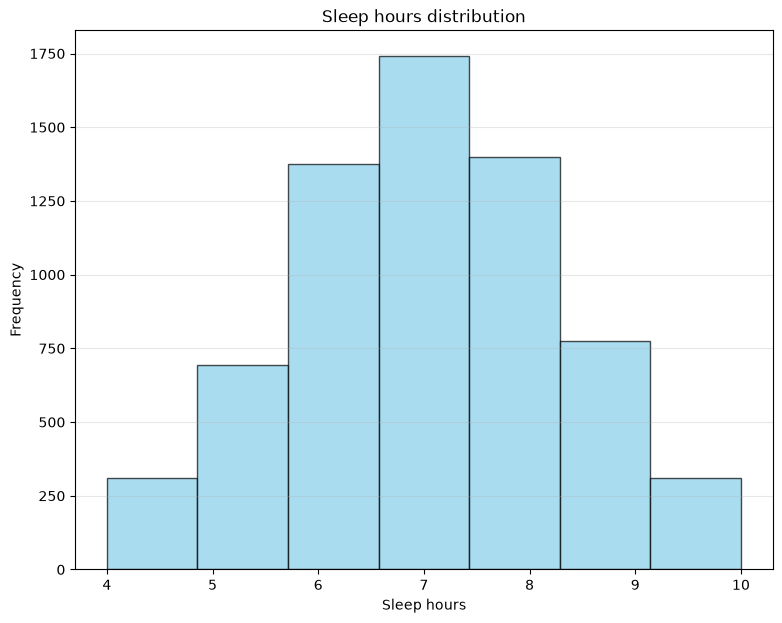

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
fig.set_size_inches(9, 7)

data = pd.read_csv("student_perfomance.csv")
sleep_hours = data["Sleep_Hours"]

ax.hist(sleep_hours, bins=7, color='skyblue', edgecolor='black', alpha=0.7)
ax.set_xlabel("Sleep hours")
ax.set_ylabel("Frequency")
ax.set_title("Sleep hours distribution")

plt.grid(True, alpha=0.3, axis='y')
plt.show()

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

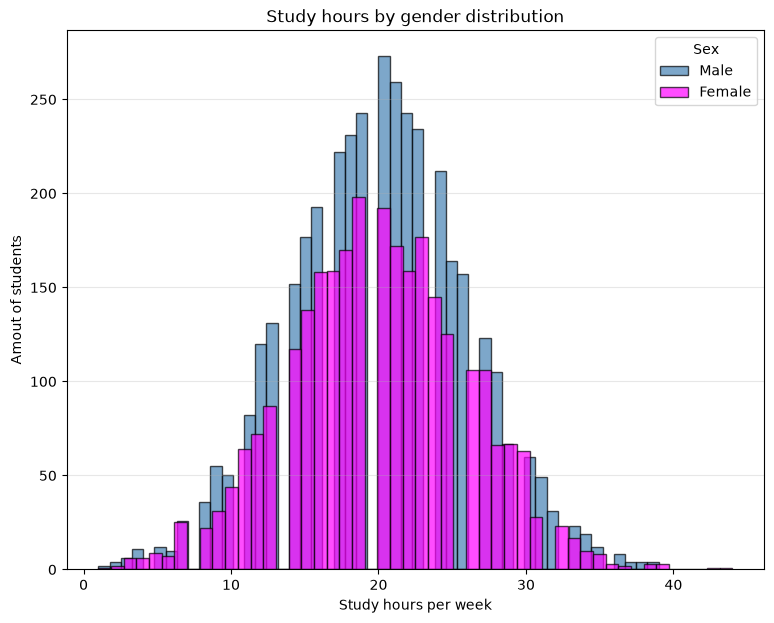

In [ ]:
fig, ax = plt.subplots()
fig.set_size_inches(9, 7)

data = pd.read_csv("student_perfomance.csv")

genders = data['Gender'].unique()

for gender in genders:
    data_where = data[data['Gender'] == gender]
    color = 'steelblue'
    if gender == 'Female':
        color = 'magenta'
    plt.hist(data_where['Hours_Studied'], bins=50, alpha=0.7, label=gender, color=color, edgecolor='black')

ax.set_xlabel("Study hours per week")
ax.set_ylabel("Amout of students")
ax.set_title("Study hours by gender distribution")
plt.legend(title='Sex')

plt.grid(True, alpha=0.3, axis='y')
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

Ответ: Результаты финального экзамена не зависит от результата предыдущего экзамена.
Получается, что те, кто сдал первый эказмен на 80-100, в большинстве получили 60~75 баллов.
То же верно и для тех, кто писал первый экзамен на 50-80.
Да, есть некоторые студенты, которые набрали сильно больше баллов, но опять-таки, стоит смотреть на другие факторы, ведь в данном случае явной корреляции не наблюдается.

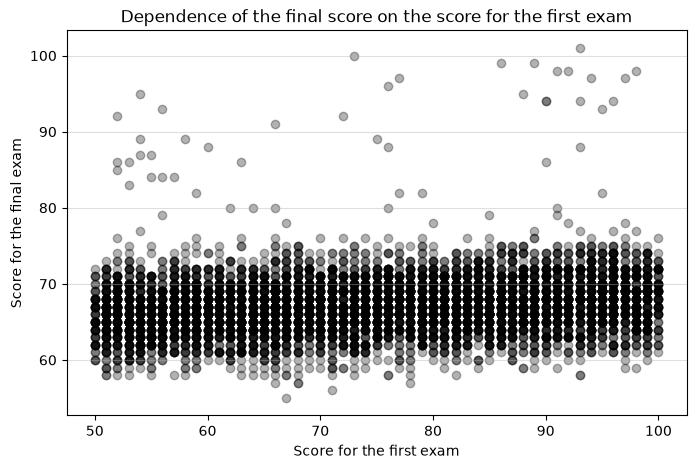

In [35]:
data = pd.read_csv("student_perfomance.csv")

fig, ax = plt.subplots()
fig.set_size_inches(8, 5)

ax.scatter(data['Previous_Scores'], data['Exam_Score'], alpha=0.3, color='black')

ax.set_xlabel('Score for the first exam')
ax.set_ylabel('Score for the final exam')
ax.set_title('Dependence of the final score on the score for the first exam')
ax.grid(True, alpha=0.4, axis='y')

plt.show()

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

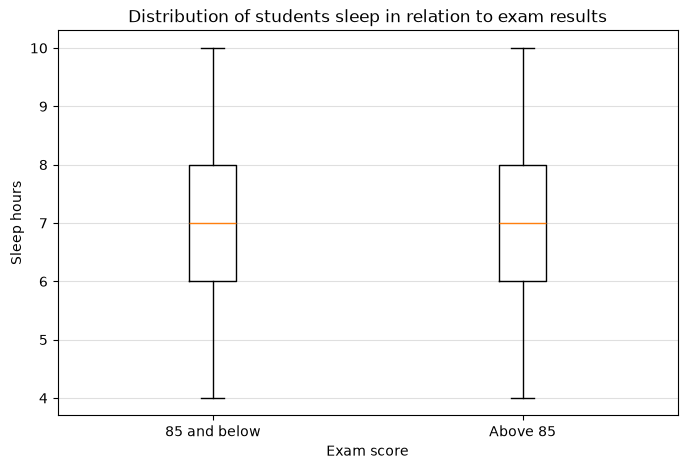

In [43]:
below_85 = data[data['Exam_Score'] <= 85]['Sleep_Hours'].dropna()
above_85 = data[data['Exam_Score'] > 85]['Sleep_Hours'].dropna()

fig, ax = plt.subplots()
fig.set_size_inches(8, 5)

ax.boxplot([below_85, above_85], tick_labels=['85 and below', 'Above 85'])

ax.set_xlabel('Exam score')
ax.set_ylabel('Sleep hours')
ax.set_title('Distribution of students sleep in relation to exam results')
ax.grid(True, alpha=0.4, axis='y')

plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

Ответ: нет, это неправда. Если бы была прямая зависимость, то люди, которые занимались с репетиторами больше всех набрали бы больше всего баллов (чего, собственно, не произошло).

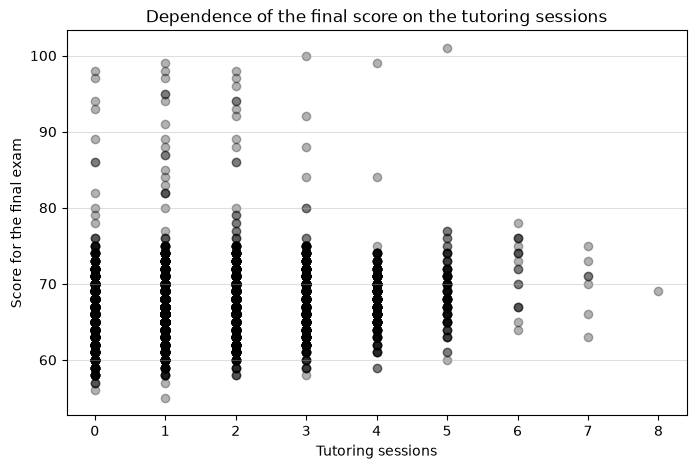

In [44]:
fig, ax = plt.subplots()
fig.set_size_inches(8, 5)

ax.scatter(data['Tutoring_Sessions'], data['Exam_Score'], alpha=0.3, color='black')

ax.set_xlabel('Tutoring sessions')
ax.set_ylabel('Score for the final exam')
ax.set_title('Dependence of the final score on the tutoring sessions')
ax.grid(True, alpha=0.4, axis='y')

plt.show()

6. Как физическая активность влияет на успеваемость?

Ответ: нет зависимости успеваемости от физической активности. Медиана (линия внутри бокса) примерно на одном уровне (как, собственно, и сами боксы), то есть в среднем студент сдает на +- одинаковые баллы

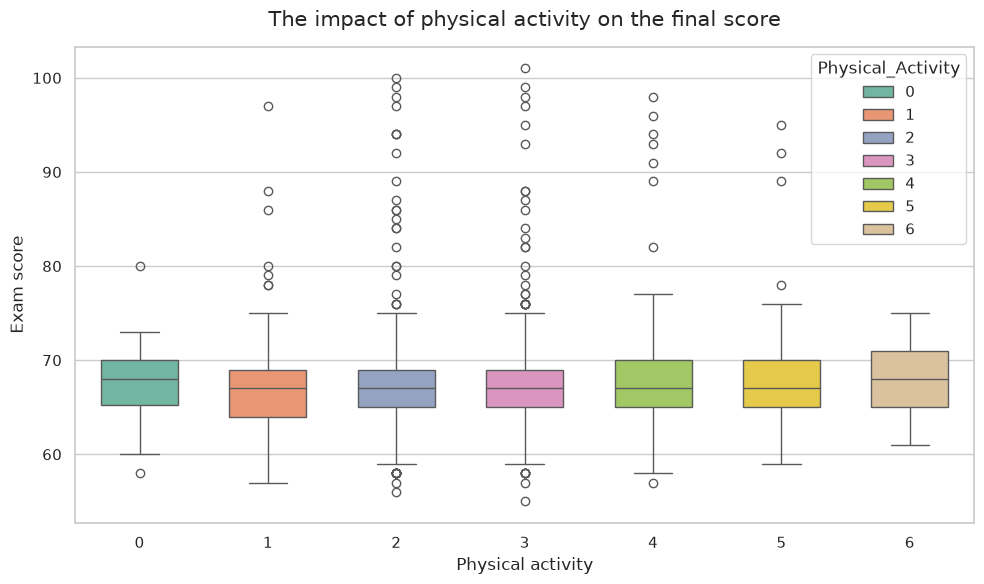

In [47]:
import seaborn as sns

data = pd.read_csv('student_perfomance.csv')

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots()
fig.set_size_inches((10, 6))

sns.boxplot(data=data, x='Physical_Activity', y='Exam_Score', hue='Physical_Activity', palette='Set2', width=0.6)

ax.set_xlabel('Physical activity', fontsize=12)
ax.set_ylabel('Exam score', fontsize=12)
ax.set_title('The impact of physical activity on the final score', fontsize=15, pad=15)

plt.tight_layout()
plt.show()

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

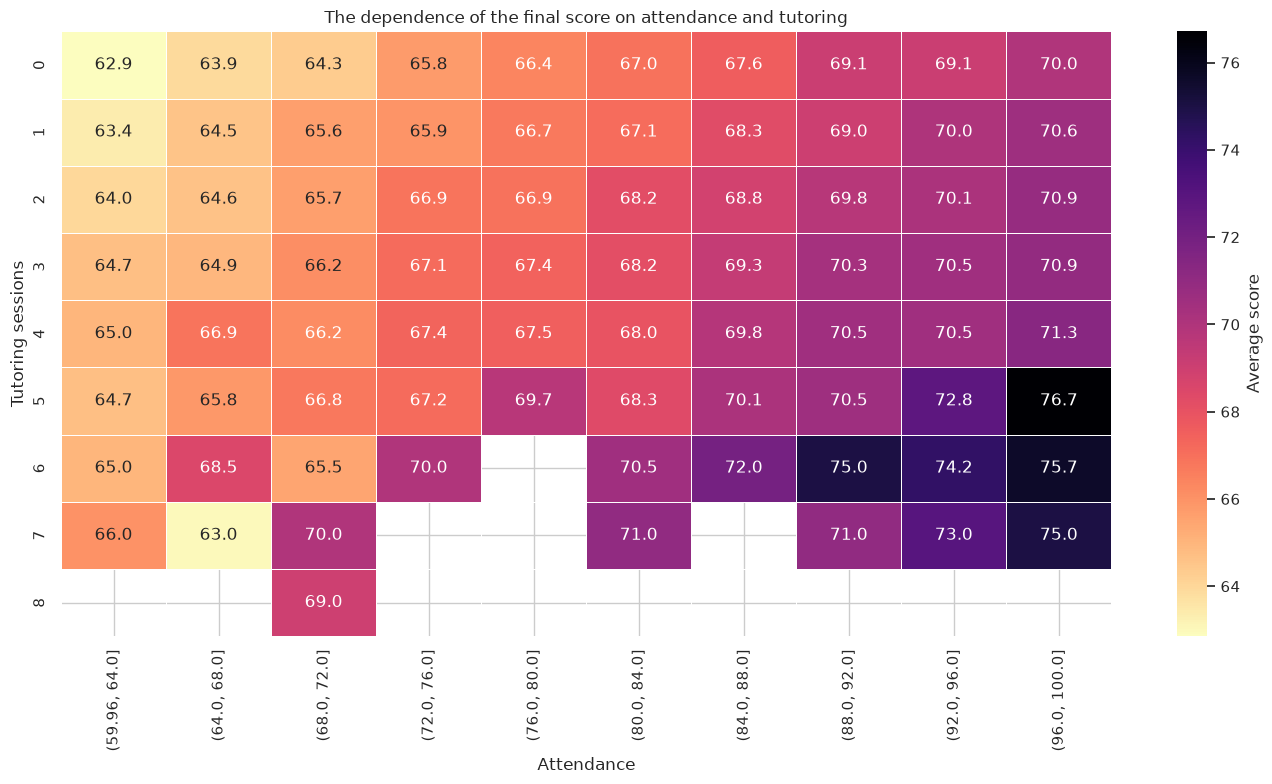

In [53]:
data['Attendance_Bin'] = pd.cut(data['Attendance'], bins=10)

heatmap_data = data.pivot_table(index='Tutoring_Sessions', columns='Attendance_Bin', values='Exam_Score', aggfunc='mean')

fig, ax = plt.subplots()
fig.set_size_inches(14, 8)

sns.heatmap(data=heatmap_data, cmap='magma_r', annot=True, fmt=".1f", linewidths=.5, cbar_kws={'label': 'Average score'})

ax.set_xlabel('Attendance')
ax.set_ylabel('Tutoring sessions')
ax.set_title('The dependence of the final score on attendance and tutoring')

plt.tight_layout()
plt.show()